# Module 10: Building a rating curve for the Boise River

*The code behind GEOS 212: Water in the West, Boise State University*

A stream gage doesn't measure discharge. It measures **stage**: the height of the water surface (gage height, in feet). Measuring discharge directly takes a crew wading or boating across the river with a current meter, exactly what you'll do on the stream gaging field trip using the midsection method.

So how does USGS publish discharge every 15 minutes? It builds a **rating curve**: a relationship between stage and discharge, fitted to the crews' field measurements. The gage then converts every stage reading to discharge with that curve.

In this notebook we'll build the rating curve for **USGS 13206000, Boise River at Glenwood Bridge**, from the real field measurements USGS crews have made there since 1972. Then we'll see why the curve has to keep being checked: rivers move their beds.

**Where are we in the water year?** In the *river*.

> **New to Jupyter?** Click a gray code cell and press **Shift + Enter** to run it. Run the cells in order.

## 1. Setup

In [1]:
import io
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import requests

# The GEOS 212 "water" colors, so these plots match the lecture slides
INK, DEEP, RIVER, GLACIER, OCHRE, BASALT, MIST = (
    "#14303F", "#0E4D64", "#137C8B", "#4FB0C6", "#D9822B", "#5B6770", "#EAF4F4")
plt.rcParams.update({"figure.dpi": 110, "font.size": 12,
                     "axes.spines.top": False, "axes.spines.right": False})

# If a live download fails (no internet, or an agency changes its website),
# we fall back to a copy of the data saved in this repository.
DATA_DIR = Path("../data")
DATA_URL = "https://raw.githubusercontent.com/LejoFlores/geos212-code/main/data/"

def fetch_text(url, cache_name):
    """Download text from `url`. Save a copy as data/<cache_name>.
    If the download fails, use the saved copy instead."""
    try:
        r = requests.get(url, timeout=60)
        r.raise_for_status()
        text = r.text
        if DATA_DIR.exists():
            (DATA_DIR / cache_name).write_text(text)
        print(f"Downloaded live data -> {cache_name}")
    except Exception as err:
        print(f"Live download failed ({type(err).__name__}); using saved copy of {cache_name}")
        local = DATA_DIR / cache_name
        text = local.read_text() if local.exists() else requests.get(DATA_URL + cache_name, timeout=60).text
    return text

## 2. Getting the field measurements

USGS's newer data service, the [Water Data API](https://api.waterdata.usgs.gov/), shares every field measurement. Each *reading* in the download is one number from one field visit: a discharge, a gage height, or a few other things. The download is in **JSON**, a common format for data from web services: nested lists and dictionaries, which Python reads easily.

In [2]:
import json

url = ("https://api.waterdata.usgs.gov/ogcapi/v0/collections/field-measurements/items"
       "?f=json&monitoring_location_id=USGS-13206000&limit=10000")
data = json.loads(fetch_text(url, "usgs_13206000_field_measurements.json"))

readings = pd.DataFrame([feature["properties"] for feature in data["features"]])
readings["value"] = pd.to_numeric(readings["value"], errors="coerce")
readings["time"] = pd.to_datetime(readings["time"], utc=True)
print(f"{len(readings):,} readings")
readings["reading_type"].value_counts()

Downloaded live data -> usgs_13206000_field_measurements.json
1,146 readings


reading_type
Discharge           543
MeanGageHeight      532
ReferencePrimary     71
Name: count, dtype: int64

## 3. Pairing stage with discharge

To build a rating curve we need *pairs*: the discharge the crew measured, and the gage height at the time. Real data is messy, so this takes some care:

* Some visits include **two** discharge measurements.
* Some gage-height readings are `ReferencePrimary` checks of the gage itself, not the river stage during the measurement. We use only `MeanGageHeight`.

So for each discharge reading, we take the `MeanGageHeight` from the **same field visit** that is **closest in time**.

In [3]:
q = readings[readings.reading_type == "Discharge"][["field_visit_id", "time", "value"]].rename(columns={"value": "Q"})
h = readings[readings.reading_type == "MeanGageHeight"][["field_visit_id", "time", "value"]].rename(columns={"value": "h", "time": "h_time"})

pairs = q.merge(h, on="field_visit_id")                  # every discharge with every gage height from its visit
pairs["gap"] = (pairs.time - pairs.h_time).abs()
pairs = (pairs.sort_values("gap")
              .drop_duplicates(["field_visit_id", "time"])  # keep the closest gage height for each discharge
              .dropna(subset=["Q", "h"])
              .sort_values("time"))
pairs["wy"] = pairs.time.dt.year + (pairs.time.dt.month >= 10)
print(f"{len(pairs)} paired measurements, {pairs.time.min():%Y} to {pairs.time.max():%Y}")
pairs[["time", "h", "Q"]].tail()

531 paired measurements, 1972 to 2026


,time,h,Q
510,2026-06-30 15:16:34+00:00,4.20,729.0
574,2026-06-30 16:02:12+00:00,4.23,727.0
187,2026-08-12 18:59:54+00:00,4.07,619.0
502,2026-09-30 19:43:00+00:00,3.59,380.0
451,2026-10-19 15:35:05+00:00,3.19,215.0


## 4. Fitting the rating curve

Rating curves are usually a **power law**:

$$Q = C\,(h - e)^{b}$$

* $h$ is the stage (ft) and $Q$ the discharge (cfs).
* $e$ is the stage of **zero flow**: the gage height at which water would stop flowing over the lowest point of the channel's control (a riffle or rock bar downstream).
* $C$ and $b$ describe the shape of the channel. Wider, shallower channels give different values than narrow, deep ones.

Taking the log of both sides turns it into something close to a straight line:

$$\ln Q = \ln C + b\,\ln(h - e)$$

We'll find the $C$, $e$ and $b$ that best fit the measurements with `scipy.optimize.curve_fit`, a more general cousin of the `np.polyfit` you used in Lab 07. Rivers change, so we use only the most recent three water years (2024-2026).

In [4]:
from scipy.optimize import curve_fit

def log_rating(h, lnC, e, b):
    return lnC + b * np.log(np.clip(h - e, 1e-6, None))   # clip avoids log of a negative number

def fit_rating(df):
    params, _ = curve_fit(log_rating, df.h, np.log(df.Q), p0=[5, 2, 2], maxfev=20000)
    lnC, e, b = params
    return np.exp(lnC), e, b

recent = pairs[pairs.wy.between(2024, 2026)]
C, e, b = fit_rating(recent)
scatter = 100 * (recent.Q / (C * (recent.h - e) ** b) - 1)
print(f"n = {len(recent)} measurements")
print(f"Q = {C:.1f} (h - {e:.2f})^{b:.2f}")
print(f"Measurements scatter about the curve by +/- {scatter.std():.0f}% (one standard deviation)")

n = 31 measurements
Q = 193.7 (h - 2.18)^1.75
Measurements scatter about the curve by +/- 6% (one standard deviation)


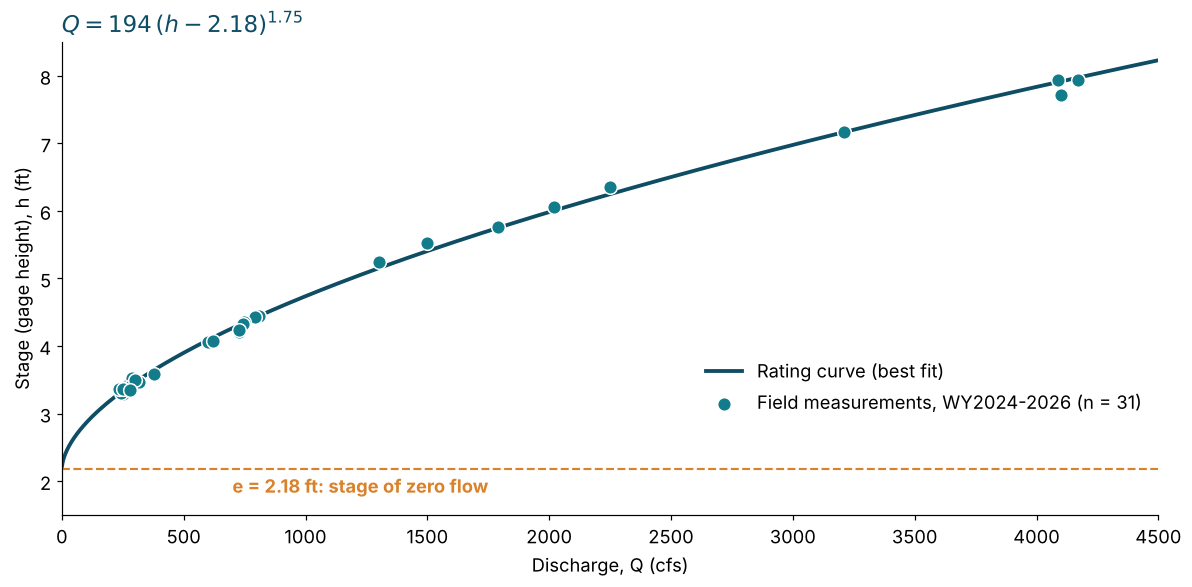

In [5]:
hh = np.linspace(e + 0.05, 8.4, 300)
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(C * (hh - e) ** b, hh, color=DEEP, lw=2.5, label="Rating curve (best fit)")
ax.scatter(recent.Q, recent.h, s=80, color=RIVER, edgecolor="white", zorder=3,
           label=f"Field measurements, WY2024-2026 (n = {len(recent)})")
ax.axhline(e, color=OCHRE, ls="--", lw=1.4)
ax.text(700, e - 0.25, f"e = {e:.2f} ft: stage of zero flow", color=OCHRE, fontweight="bold", va="center")
ax.set_xlabel("Discharge, Q (cfs)"); ax.set_ylabel("Stage (gage height), h (ft)")
ax.set_xlim(0, 4500); ax.set_ylim(1.5, 8.5)
ax.set_title(f"$Q = {C:.0f}\\,(h - {e:.2f})^{{{b:.2f}}}$", loc="left", color=DEEP, fontsize=15)
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1, 0.18))
plt.tight_layout()

By convention, rating curves are drawn with stage on the y-axis (it's "up" in the river) even though we use stage to predict discharge.

## 5. Using the rating curve

On **April 17, 2026**, a USGS crew measured the river at Glenwood. Let's pretend we only have the gage reading and use our curve to estimate discharge, then compare with what the crew measured.

In [6]:
visit = recent[recent.time.dt.strftime("%Y-%m-%d") == "2026-04-17"].iloc[0]
estimate = C * (visit.h - e) ** b
print(f"Gage height: {visit.h:.2f} ft")
print(f"Rating curve estimate: {C:.1f} x ({visit.h:.2f} - {e:.2f})^{b:.2f} = {estimate:,.0f} cfs")
print(f"Crew measured: {visit.Q:,.0f} cfs  (difference {100 * (estimate / visit.Q - 1):+.1f}%)")

Gage height: 5.76 ft
Rating curve estimate: 193.7 x (5.76 - 2.18)^1.75 = 1,800 cfs
Crew measured: 1,790 cfs  (difference +0.6%)


## 6. Rivers move: the rating shifts

A rating curve only works while the channel stays the same. Floods scour and deposit gravel, vegetation grows in and gets ripped out, and the "zero flow" point moves. That's why USGS crews keep returning several times a year: each measurement checks whether the curve has shifted.

The Boise River ran high for months in the big snow year of 2017. Let's fit a second curve to the measurements from **before** that flood (WY2015-2016) and compare.

WY2015-2016 (n = 24): Q = 174.5 (h - 2.93)^1.84
WY2024-2026 (n = 31): Q = 193.7 (h - 2.18)^1.75
260 cfs read 4.2 ft on the gage then, 3.4 ft now
850 cfs read 5.3 ft on the gage then, 4.5 ft now


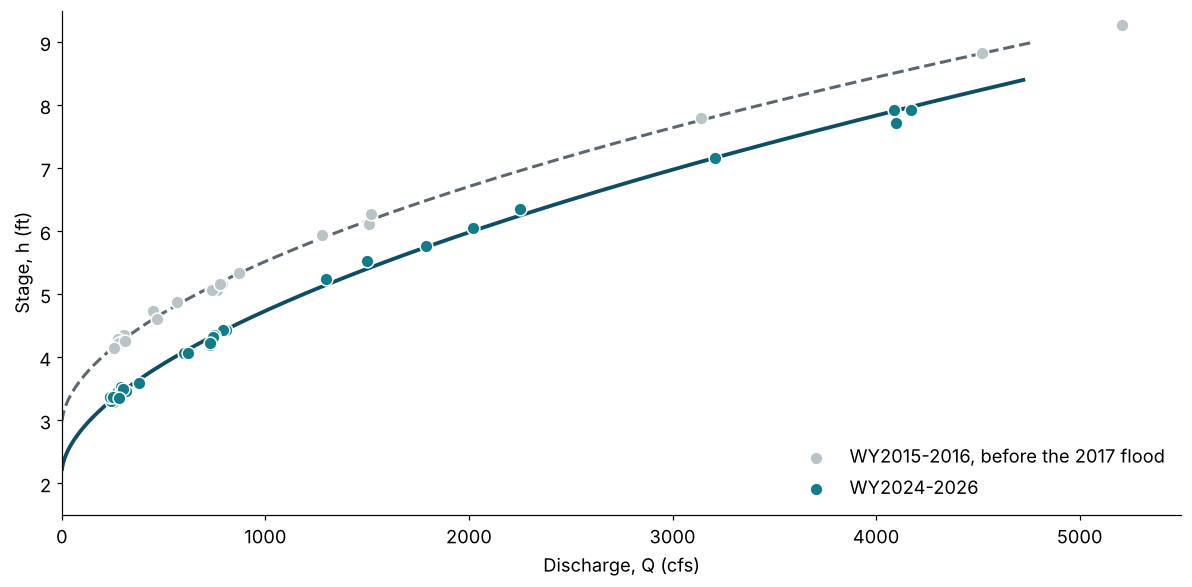

In [7]:
before = pairs[pairs.wy.between(2015, 2016)]
C0, e0, b0 = fit_rating(before)
print(f"WY2015-2016 (n = {len(before)}): Q = {C0:.1f} (h - {e0:.2f})^{b0:.2f}")
print(f"WY2024-2026 (n = {len(recent)}): Q = {C:.1f} (h - {e:.2f})^{b:.2f}")

stage_for = lambda Q, C, e, b: e + (Q / C) ** (1 / b)    # the rating curve solved for h
for flow in [260, 850]:
    print(f"{flow} cfs read {stage_for(flow, C0, e0, b0):.1f} ft on the gage then, {stage_for(flow, C, e, b):.1f} ft now")

hh0 = np.linspace(e0 + 0.05, 9.0, 300)
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(C0 * (hh0 - e0) ** b0, hh0, color=BASALT, ls="--", lw=2)
ax.scatter(before.Q, before.h, s=70, color="#B8C4C8", edgecolor="white", zorder=3, label="WY2015-2016, before the 2017 flood")
ax.plot(C * (hh - e) ** b, hh, color=DEEP, lw=2.5)
ax.scatter(recent.Q, recent.h, s=70, color=RIVER, edgecolor="white", zorder=3, label="WY2024-2026")
ax.set_xlabel("Discharge, Q (cfs)"); ax.set_ylabel("Stage, h (ft)")
ax.set_xlim(0, 5500); ax.set_ylim(1.5, 9.5)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()

The same flow now sits almost a foot lower on the gage. If USGS had kept using the old curve, every discharge it published would be wrong. (Can you work out whether it would be too high or too low?)

## 7. Your turn

1. **Use the old curve.** Estimate the April 17, 2026 discharge with the WY2015-2016 curve (`C0, e0, b0`). How far off is it, and in which direction? Who downstream might care?
2. **Watch the curve drift.** Fit a curve to every three-year window (1975-1977, 1978-1980, and so on) and plot $e$ (the zero-flow stage) through time. When did the channel change most? Do those times match big floods? (Look up the Boise River's peak flows.)
3. **Straight line test.** Plot $\ln Q$ against $\ln(h - e)$ using your fitted $e$. Are the points close to a straight line? What is the slope?
4. **Extrapolation.** The highest flow in the recent measurements is about 4,000 cfs. Use the curve to estimate the stage for 10,000 cfs. Why should you be cautious about that number? (Hint: what happens when the river spills out of its channel?)

### Why code?
Pairing 1,100 readings by visit and time, fitting a three-parameter curve, and refitting it for any window of years is a few lines of code. In a spreadsheet it would be hours of copying and pasting, and much easier to get wrong.

---
*Data: USGS Water Data API, field measurements for 13206000. Recent values are partly provisional.*